# Stage 2e — Paganin Object Initialization

In [1]:
# --- paths ----------------------------------------------------------
# From config_steps15.conf, which holds every path for the holotomography scan.
# Edit that file, not this cell.
from holotomocupy.config import parse_args_coded_steps15
_cfg = parse_args_coded_steps15('config_steps15.conf')
WITH_CA = _cfg.path   # processed data for this sample


In [2]:
import numpy as np
import cupy as cp
import h5py
import matplotlib.pyplot as plt
%matplotlib inline
from holotomocupy.propagation import Propagation

PATH_H5    = f'{WITH_CA}/codedHT.h5'
PATH_OBJ   = f'{WITH_CA}/obj_init.npy'

# Stage 0's products: in config_step0.conf's nfp/ folder, NOT WITH_CA (ht/) --
# _cfg already resolved these to absolute paths, so use them directly rather
# than rebuilding from WITH_CA.
PATH_H5_CA = _cfg.nfp_file
PATH_CODE  = _cfg.code_file
PATH_PRB   = _cfg.prb_file

# Geometry + propagate code and probe to detector
with h5py.File(PATH_H5, 'r') as f:
    energy  = float(f['/exchange/energy'][0])
    det_px  = float(f['/exchange/detector_pixelsize'][0])
    fdd     = float(f['/exchange/focusdetectordistance'][0])
    z1      = float(f['/exchange/z1'][0])
    ntheta, nz, n = f['/exchange/pdata'].shape
    theta_deg   = f['/exchange/theta'][:].astype('float32')       # (ntheta,)
    shifts_code = f['/exchange/shifts_code'][:].astype('float32') # (ntheta, 2) [row, col] px
    shifts_cor  = f['/exchange/shifts_cor'][:].astype('float32')  # (ntheta, 2) [row, col] px

with h5py.File(PATH_H5_CA, 'r') as f:
    z1_code = float(f['/exchange/z1'][0])

# Rotation axis offset [row, col] un-binned px — keep in sync with rec_ht_new.py.
# Convention: index 0 = row shift, index 1 = col shift  (matches CUDA s_kernel: r[2*tz+0]=row, r[2*tz+1]=col).
ROT_AXIS_OFFSET_PX = np.array([0.0, -24.0], dtype='float32')

# Per-angle object position (un-binned px).
# Each Paganin projection is shifted by -pos_obj[k] to centre the rotation axis.
pos_obj = shifts_cor + ROT_AXIS_OFFSET_PX   # (ntheta, 2) [row, col]

wavelength    = 1.24e-9 / energy
z2            = fdd - z1
magnification = fdd / z1
distance      = z1 * z2 / fdd
voxelsize     = det_px / magnification

z2c                     = z1 - z1_code
magnification_code      = z1 / z1_code
distance_code           = (z1_code * z2c) / (z1_code + z2c)
norm_magnification_code = magnification_code / (z1_code / z1)
distance_code           = distance_code * norm_magnification_code**2
distance_code           = distance_code * (z1_code / z1)**2

code = np.load(PATH_CODE).astype('complex64')
prb  = np.load(PATH_PRB ).astype('complex64')
ncode_full = code.shape[0]   # 8192

cl_prop           = Propagation(n,          nz,         1, 1, wavelength, voxelsize, [distance])
cl_prop_code      = Propagation(n,          nz,         1, 1, wavelength, voxelsize, [distance_code])
cl_prop_8192      = Propagation(ncode_full, ncode_full, 1, 1, wavelength, voxelsize, [distance])
cl_prop_code_8192 = Propagation(ncode_full, ncode_full, 1, 1, wavelength, voxelsize, [distance_code])

prb_gpu  = cp.array(prb)
prb_samp = cl_prop_code.D(prb_gpu, 0)
ref_gpu  = cl_prop.D(prb_samp, 0)
ref      = cp.abs(ref_gpu).real**2
ref      = ref.get()
del prb_gpu, prb_samp, ref_gpu

print('Computing cdata (8192×8192)...')
code_gpu       = cp.array(code)
code_samp_8192 = cl_prop_code_8192.D(code_gpu, 0)
cdata_gpu      = cl_prop_8192.D(code_samp_8192, 0)
cdata          = cp.abs(cdata_gpu).real**2
del code_gpu, code_samp_8192, cdata_gpu
cdata = cdata.get()

print(f'ntheta={ntheta}  nz={nz}  n={n}')
print(f'ref  : {ref.shape}  [{ref.min():.4f}, {ref.max():.4f}]')
print(f'cdata: {cdata.shape}  [{cdata.min():.4f}, {cdata.max():.4f}]')

/home/beams0/CEKMEKCI/Desktop/holotomocupy/src/holotomocupy/propagation.py:44: UserWarning: nvcc not found (NVCC='nvcc'). Set NVCC env var or add nvcc to PATH. Falling back to cuPy FFT.
  self._use_cufftdx = cufftdx_available()


Computing cdata (8192×8192)...
ntheta=7200  nz=2048  n=2048
ref  : (2048, 2048)  [0.0546, 4.4314]
cdata: (8192, 8192)  [0.0948, 3.5973]


In [3]:
def multiPaganin(data, dist, wavelength, voxelsize, delta_beta, alpha):
    """Single-distance Paganin phase retrieval on a 2D CuPy array."""
    fy = cp.fft.fftfreq(data.shape[-2], d=voxelsize).astype('float32')
    fx = cp.fft.fftfreq(data.shape[-1], d=voxelsize).astype('float32')
    fx, fy    = cp.meshgrid(fx, fy)
    rad_freq  = cp.fft.fft2(data)
    taylorExp = 1 + wavelength * dist * cp.pi * delta_beta * (fx**2 + fy**2)
    numerator   = taylorExp * rad_freq
    denominator = taylorExp**2 + alpha
    phase = cp.log(cp.real(cp.fft.ifft2(numerator / denominator)))
    return delta_beta * 0.5 * phase

def fourier_shift_2d(arr, dc, dr):
    """Shift a 2D real CuPy array by (dc, dr) pixels via Fourier phase ramp.
    arr axes: [row, col].  dc = col shift, dr = row shift."""
    nr, nc = arr.shape
    fr = cp.fft.fftfreq(nr).astype('float32')
    fc = cp.fft.fftfreq(nc).astype('float32')
    Fc, Fr = cp.meshgrid(fc, fr)
    ramp = cp.exp(-2j * cp.pi * (Fr * dr + Fc * dc)).astype('complex64')
    return cp.fft.ifft2(cp.fft.fft2(arr.astype('complex64')) * ramp).real.astype('float32')

rec_paganin = np.zeros((ntheta, nz, n), dtype='float32')

with h5py.File(PATH_H5, 'r') as f:
    for k in range(ntheta):
        frame = f['/exchange/pdata'][k].astype('float32')   # (nz, n)

        dy = int(round(shifts_code[k, 0]))
        dx = int(round(shifts_code[k, 1]))
        cr = ncode_full // 2 - dy
        cc = ncode_full // 2 - dx
        cdata_crop = cdata[cr - nz//2 : cr + nz//2,
                           cc - n//2  : cc + n//2]

        proj  = frame / (cdata_crop * ref + 1e-6)
        phase = multiPaganin(cp.array(proj), distance, wavelength, voxelsize, 20, 1e-3)

        # Shift to centre the rotation axis: -pos_obj[k] = -(shifts_cor + ROT_AXIS_OFFSET_PX)
        # pos_obj convention [row, col]: index 0 = row shift, index 1 = col shift.
        # fourier_shift_2d: dc = col shift, dr = row shift → indices are swapped.
        phase = fourier_shift_2d(phase, dc=-pos_obj[k, 1], dr=-pos_obj[k, 0])

        rec_paganin[k] = phase.get()

        if k % 200 == 0:
            print(f'  k={k:5d}/{ntheta}  phase [{rec_paganin[k].min():.4f}, {rec_paganin[k].max():.4f}]')

print(f'\nrec_paganin: {rec_paganin.shape}  [{rec_paganin.min():.4f}, {rec_paganin.max():.4f}]')

  k=    0/7200  phase [-0.6890, 0.2308]
  k=  200/7200  phase [-0.9801, 0.0139]
  k=  400/7200  phase [-0.9524, 0.0237]
  k=  600/7200  phase [-1.0269, 0.0704]
  k=  800/7200  phase [-0.9229, 0.1593]
  k= 1000/7200  phase [-0.9555, 0.0191]
  k= 1200/7200  phase [-1.0317, 0.0497]
  k= 1400/7200  phase [-1.0529, 0.1283]
  k= 1600/7200  phase [-0.9699, 0.1680]
  k= 1800/7200  phase [-0.9901, 0.1529]
  k= 2000/7200  phase [-0.9994, 0.0398]
  k= 2200/7200  phase [-1.0214, 0.0557]
  k= 2400/7200  phase [-0.9149, 0.1143]
  k= 2600/7200  phase [-0.9566, -0.0163]
  k= 2800/7200  phase [-0.9537, -0.0217]
  k= 3000/7200  phase [-0.9584, 0.0272]
  k= 3200/7200  phase [-0.9758, -0.0123]
  k= 3400/7200  phase [-0.9981, 0.0409]
  k= 3600/7200  phase [-0.9928, -0.0013]
  k= 3800/7200  phase [-0.9876, 0.0673]
  k= 4000/7200  phase [-1.0267, 0.0522]
  k= 4200/7200  phase [-1.0180, -0.0043]
  k= 4400/7200  phase [-1.0217, 0.0915]
  k= 4600/7200  phase [-0.9558, 0.0637]
  k= 4800/7200  phase [-0.9641, 0.1

In [4]:
import threading
from holotomocupy.tomo import Tomo

theta_rad = np.deg2rad(theta_deg)
NGPU      = 4
NCHUNK    = 2

# FBP instead of 64 CG iterations: ~66x faster (measured 0.20 s vs 14.57 s per
# 2 slices at this geometry), at rel_err 0.145 vs 0.067 against a known volume.
# Plenty for an initial guess.
#
# But Tomo.fbp's norm_const (= sqrt(n/ntheta)*n/nd) leaves the result short by
# ~(pi/4)*sqrt(ntheta/n), so its ABSOLUTE scale still depends on the angle
# count -- which a true FBP must not.  Verified over six geometries
# (n=256/512 x ntheta=375..3000): the shortfall is exactly proportional to
# sqrt(ntheta/n), with a constant measuring 0.774-0.778, i.e. pi/4 to ~1%.
# At n=2048, ntheta=7200 fbp lands at 0.693x of what rec_tomo converges to,
# and cell 6 saves straight into obj_init.npy with no normalisation, so this
# factor is not optional.
#
# pi/4 is only good to ~1%.  To pin it on real data, run one z-chunk both ways
# and take sum(cg*fbp)/sum(fbp*fbp).
FBP_SCALE  = (np.pi / 4) * np.sqrt(ntheta / n)
FBP_FILTER = 'shepp'      # marginally more accurate than 'ramp' and 4x faster;
                          # 'parzen' costs another 4% of amplitude to apodisation

obj_fbp = np.zeros((nz, n, n), dtype='complex64')

def _worker(gpu_id, z_start, z_end):
    with cp.cuda.Device(gpu_id):
        cl = Tomo(n, NCHUNK, theta_rad, mask_r=0)   # no circular mask → no ring artifact
        nz_loc = z_end - z_start
        for z0 in range(0, nz_loc, NCHUNK):
            z1_ = min(z0 + NCHUNK, nz_loc)          # not `z1`: that is the sample-detector distance
            sino = cp.array(rec_paganin[:, z_start + z0 : z_start + z1_, :], dtype='complex64')
            res  = cl.fbp(sino, FBP_FILTER) * FBP_SCALE
            obj_fbp[z_start + z0 : z_start + z1_] = res.real.astype('float32').get()
        print(f'GPU {gpu_id}: done  z={z_start}:{z_end}', flush=True)

chunk_z  = nz // NGPU
z_bounds = [(g * chunk_z, (g + 1) * chunk_z if g < NGPU - 1 else nz) for g in range(NGPU)]
threads  = [threading.Thread(target=_worker, args=(g, zs, ze)) for g, (zs, ze) in enumerate(z_bounds)]

print(f'FBP_SCALE = {FBP_SCALE:.4f}  (filter {FBP_FILTER!r}, ntheta={ntheta}, n={n})')
for t in threads: t.start()
for t in threads: t.join()

print(f'obj_fbp: {obj_fbp.shape}  real [{obj_fbp.real.min():.6f}, {obj_fbp.real.max():.6f}]  '
      f'imag [{obj_fbp.imag.min():.2e}, {obj_fbp.imag.max():.2e}]')

FBP_SCALE = 1.4726  (filter 'shepp', ntheta=7200, n=2048)
GPU 1: done  z=512:1024
GPU 0: done  z=0:512
GPU 3: done  z=1536:2048
GPU 2: done  z=1024:1536
obj_fbp: (2048, 2048, 2048)  real [-3.405175, 2.617662]  imag [0.00e+00, 0.00e+00]


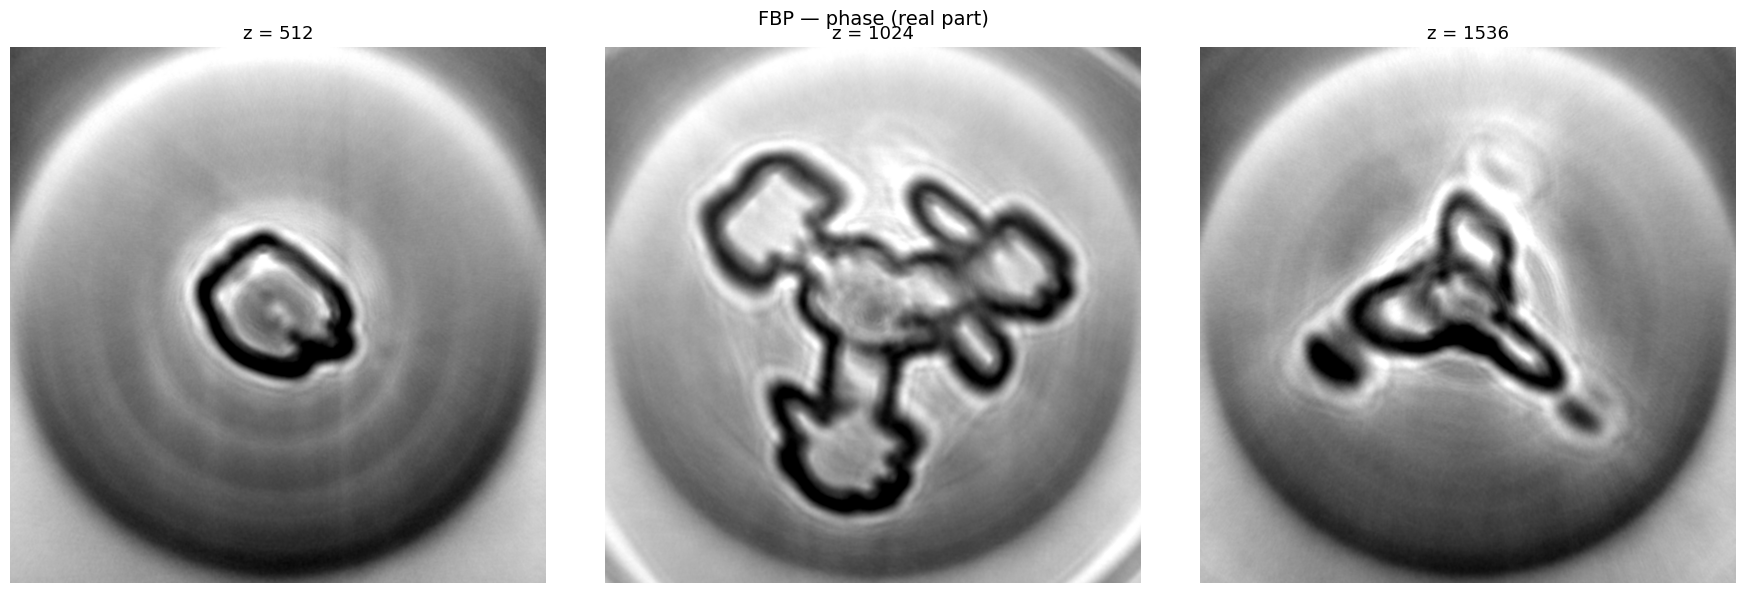

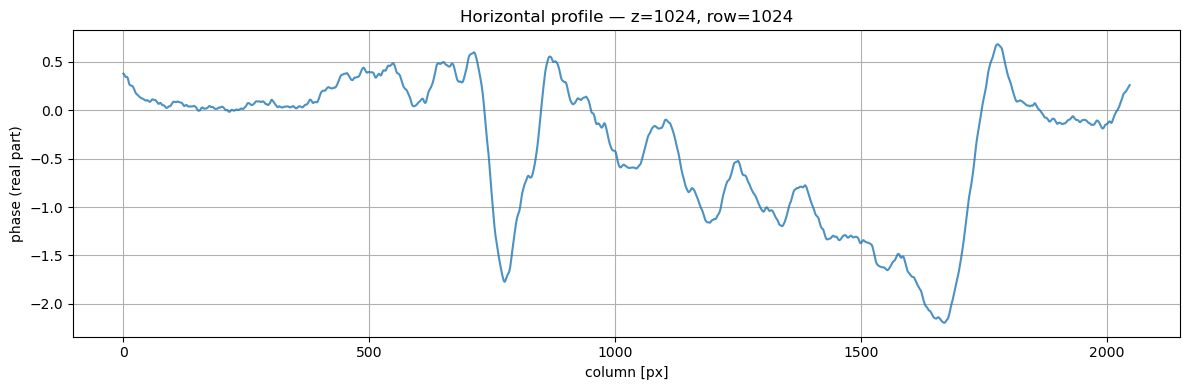

In [5]:
VIZ_Z = [nz // 4, nz // 2, 3 * nz // 4]

def _clim(sl):
    return float(np.percentile(sl, 1)), float(np.percentile(sl, 99))

fig, axes = plt.subplots(1, len(VIZ_Z), figsize=(6 * len(VIZ_Z), 6))
for col, z in enumerate(VIZ_Z):
    sl = obj_fbp[z].real   # phase maps to obj.real in exp(1j*R(u))
    vlo, vhi = _clim(sl)
    axes[col].imshow(sl, cmap='gray', vmin=vlo, vmax=vhi)
    axes[col].set_title(f'z = {z}', fontsize=13)
    axes[col].axis('off')
plt.suptitle('FBP — phase (real part)', fontsize=14)
plt.tight_layout()
plt.show()

z_mid   = nz // 2
row_mid = n  // 2
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(obj_fbp[z_mid, row_mid, :].real, alpha=0.8)
ax.set_xlabel('column [px]')
ax.set_ylabel('phase (real part)')
ax.set_title(f'Horizontal profile — z={z_mid}, row={row_mid}')
ax.grid()
plt.tight_layout()
plt.show()

In [6]:
np.save(PATH_OBJ, obj_fbp)
print(f'Saved to {PATH_OBJ}')

Saved to /data3/cekmekci/AtomiumS2_coded/ht/obj_init.npy
